# Unsupervised Machine Learning Demo
## Topics Covered:
1. **K-Means & DBSCAN**: Distance metrics, Elbow method, Silhouette analysis, Density clustering, Geo-segmentation
2. **Market Segmentation Lab**: sklearn cluster, Scaler choice, Persona crafting
3. **Visualizing Clusters**: UMAP, GeoPandas maps, Interactive hover

---

## Step 1: Install and Import Required Libraries

In [29]:
# Install required libraries
!pip install numpy pandas matplotlib seaborn scikit-learn plotly umap-learn geopandas folium

In [30]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Clustering algorithms
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.metrics.pairwise import euclidean_distances, manhattan_distances, cosine_distances

# Dimensionality reduction
from sklearn.decomposition import PCA
import umap

# Visualization
import plotly.express as px
import plotly.graph_objects as go

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


---
# Topic 1: K-Means & DBSCAN
---

## 1.1 Load Customer Dataset for Clustering

In [31]:
# Create a realistic customer dataset
np.random.seed(42)

# Generate customer data
n_customers = 500

# Create different customer segments
# Segment 1: Young, low income, high spending on entertainment
seg1_age = np.random.normal(25, 3, 150)
seg1_income = np.random.normal(30000, 5000, 150)
seg1_spending = np.random.normal(800, 100, 150)

# Segment 2: Middle-aged, medium income, moderate spending
seg2_age = np.random.normal(40, 5, 200)
seg2_income = np.random.normal(60000, 10000, 200)
seg2_spending = np.random.normal(1500, 200, 200)

# Segment 3: Older, high income, high spending
seg3_age = np.random.normal(55, 7, 150)
seg3_income = np.random.normal(90000, 15000, 150)
seg3_spending = np.random.normal(2500, 300, 150)

# Combine all segments
customer_data = pd.DataFrame({
    'CustomerID': range(1, n_customers + 1),
    'Age': np.concatenate([seg1_age, seg2_age, seg3_age]),
    'Annual_Income': np.concatenate([seg1_income, seg2_income, seg3_income]),
    'Monthly_Spending': np.concatenate([seg1_spending, seg2_spending, seg3_spending]),
    'Purchase_Frequency': np.random.randint(1, 30, n_customers),
    'Years_Customer': np.random.randint(1, 15, n_customers)
})

print("Customer Dataset Shape:", customer_data.shape)
customer_data.head(10)

Customer Dataset Shape: (500, 6)


,CustomerID,Age,Annual_Income,Monthly_Spending,Purchase_Frequency,Years_Customer
0,1,26.490142,31252.464252,717.100499,28,10
1,2,24.585207,31732.241047,743.981896,28,3
2,3,26.943066,26599.876392,874.729361,19,9
3,4,29.569090,31161.268486,861.037027,17,12
4,5,24.297540,31465.362366,797.909841,14,4
5,6,24.297589,26428.242910,811.732738,19,13
6,7,29.737638,39328.872556,927.766490,22,7
7,8,27.302304,32369.164605,740.842861,24,14
8,9,23.591577,24043.482514,854.709738,13,9
9,10,26.627680,33282.768043,779.780735,12,11


In [32]:
# Basic statistics
customer_data.describe()

,CustomerID,Age,Annual_Income,Monthly_Spending,Purchase_Frequency,Years_Customer
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,250.500000,39.940185,60310.142468,1620.971239,15.378000,7.540000
std,144.481833,13.063413,25438.259365,712.903761,8.469391,4.131166
min,1.000000,17.140765,13793.663300,587.610428,1.000000,1.000000
25%,125.750000,27.421457,34317.080471,897.423254,8.000000,4.000000
50%,250.500000,39.291013,59715.608213,1539.551039,16.000000,8.000000
75%,375.250000,49.444363,78533.126364,2245.692173,23.000000,11.000000
max,500.000000,72.078267,128695.640065,3280.504934,29.000000,14.000000


## 1.2 Distance Metrics
Distance metrics measure how similar or different data points are. Common metrics include:
- **Euclidean Distance**: Straight-line distance (most common)
- **Manhattan Distance**: Sum of absolute differences
- **Cosine Distance**: Measures angle between vectors

In [33]:
# Select features for clustering
features = ['Age', 'Annual_Income', 'Monthly_Spending']
X = customer_data[features].values

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Calculate different distance metrics between first 5 customers
sample_data = X_scaled[:5]

euclidean_dist = euclidean_distances(sample_data)
manhattan_dist = manhattan_distances(sample_data)
cosine_dist = cosine_distances(sample_data)

print("Euclidean Distance Matrix (first 5 customers):")
print(np.round(euclidean_dist, 2))
print("\nManhattan Distance Matrix (first 5 customers):")
print(np.round(manhattan_dist, 2))
print("\nCosine Distance Matrix (first 5 customers):")
print(np.round(cosine_dist, 2))

Euclidean Distance Matrix (first 5 customers):
[[0.   0.15 0.29 0.31 0.2 ]
 [0.15 0.   0.33 0.42 0.08]
 [0.29 0.33 0.   0.27 0.3 ]
 [0.31 0.42 0.27 0.   0.41]
 [0.2  0.08 0.3  0.41 0.  ]]

Manhattan Distance Matrix (first 5 customers):
[[0.   0.2  0.44 0.44 0.29]
 [0.2  0.   0.57 0.57 0.11]
 [0.44 0.57 0.   0.4  0.5 ]
 [0.44 0.57 0.4  0.   0.5 ]
 [0.29 0.11 0.5  0.5  0.  ]]

Cosine Distance Matrix (first 5 customers):
[[0.   0.   0.01 0.01 0.01]
 [0.   0.   0.01 0.01 0.  ]
 [0.01 0.01 0.   0.   0.01]
 [0.01 0.01 0.   0.   0.01]
 [0.01 0.   0.01 0.01 0.  ]]


## 1.3 Elbow Method
The Elbow Method helps us find the optimal number of clusters by plotting the Within-Cluster Sum of Squares (WCSS) for different values of K.

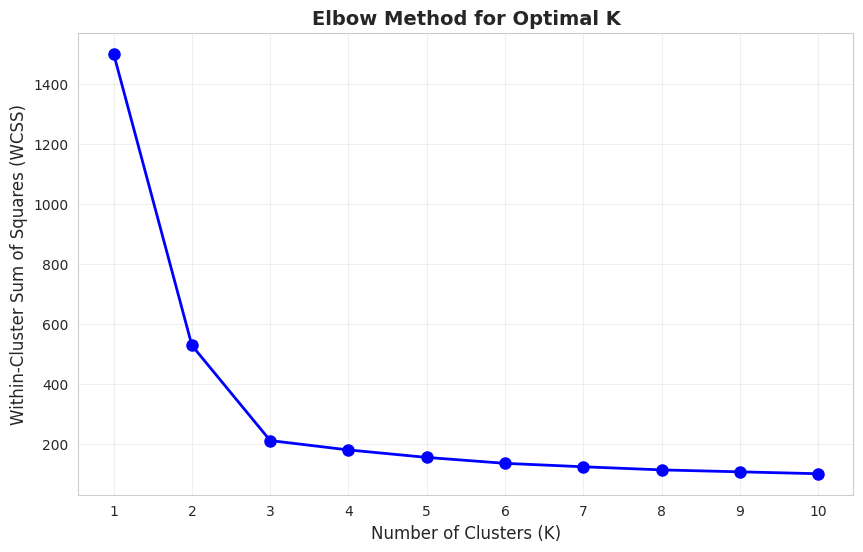

💡 Look for the 'elbow' point where the curve bends - that's often the optimal K!
   In this case, K=3 appears to be a good choice.


In [34]:
# Calculate WCSS for different numbers of clusters
wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(10, 6))
plt.plot(K_range, wcss, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('Within-Cluster Sum of Squares (WCSS)', fontsize=12)
plt.title('Elbow Method for Optimal K', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.xticks(K_range)
plt.show()

print("💡 Look for the 'elbow' point where the curve bends - that's often the optimal K!")
print("   In this case, K=3 appears to be a good choice.")

## 1.4 Silhouette Analysis
Silhouette Score measures how similar a point is to its own cluster compared to other clusters. 
- Score ranges from -1 to 1
- Higher values indicate better-defined clusters

K=2: Silhouette Score = 0.555
K=3: Silhouette Score = 0.612
K=4: Silhouette Score = 0.533
K=5: Silhouette Score = 0.534
K=6: Silhouette Score = 0.406
K=7: Silhouette Score = 0.409
K=8: Silhouette Score = 0.398
K=9: Silhouette Score = 0.388
K=10: Silhouette Score = 0.380


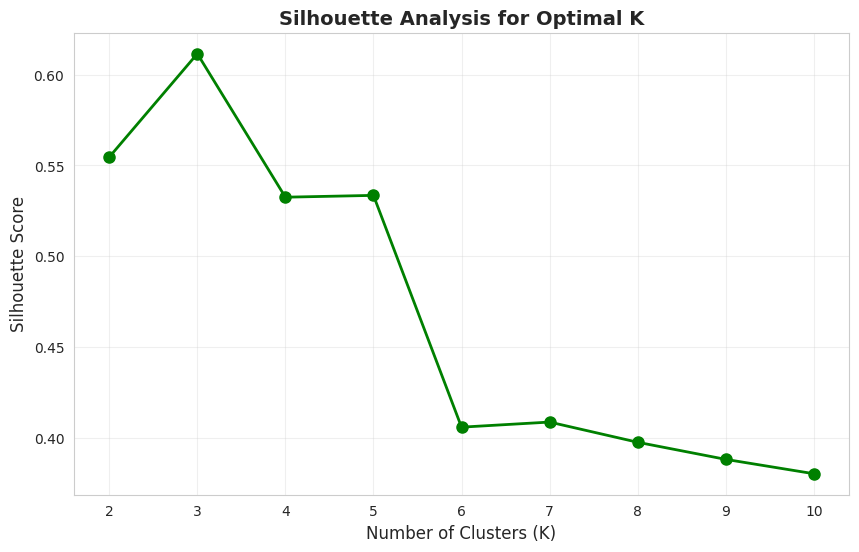


✅ Best K based on Silhouette Score: 3


In [35]:
# Calculate silhouette scores for different K values
silhouette_scores = []
K_range_sil = range(2, 11)

for k in K_range_sil:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"K={k}: Silhouette Score = {score:.3f}")

# Plot silhouette scores
plt.figure(figsize=(10, 6))
plt.plot(K_range_sil, silhouette_scores, 'go-', linewidth=2, markersize=8)
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.title('Silhouette Analysis for Optimal K', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.xticks(K_range_sil)
plt.show()

best_k = list(K_range_sil)[np.argmax(silhouette_scores)]
print(f"\n✅ Best K based on Silhouette Score: {best_k}")

## 1.5 K-Means Clustering
K-Means groups data into K clusters by minimizing the distance between points and their cluster centers.

In [36]:
# Apply K-Means with optimal K
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
customer_data['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print(f"K-Means Clustering completed with K={optimal_k}")
print("\nCluster Distribution:")
print(customer_data['KMeans_Cluster'].value_counts().sort_index())

K-Means Clustering completed with K=3

Cluster Distribution:
KMeans_Cluster
0    198
1    149
2    153
Name: count, dtype: int64


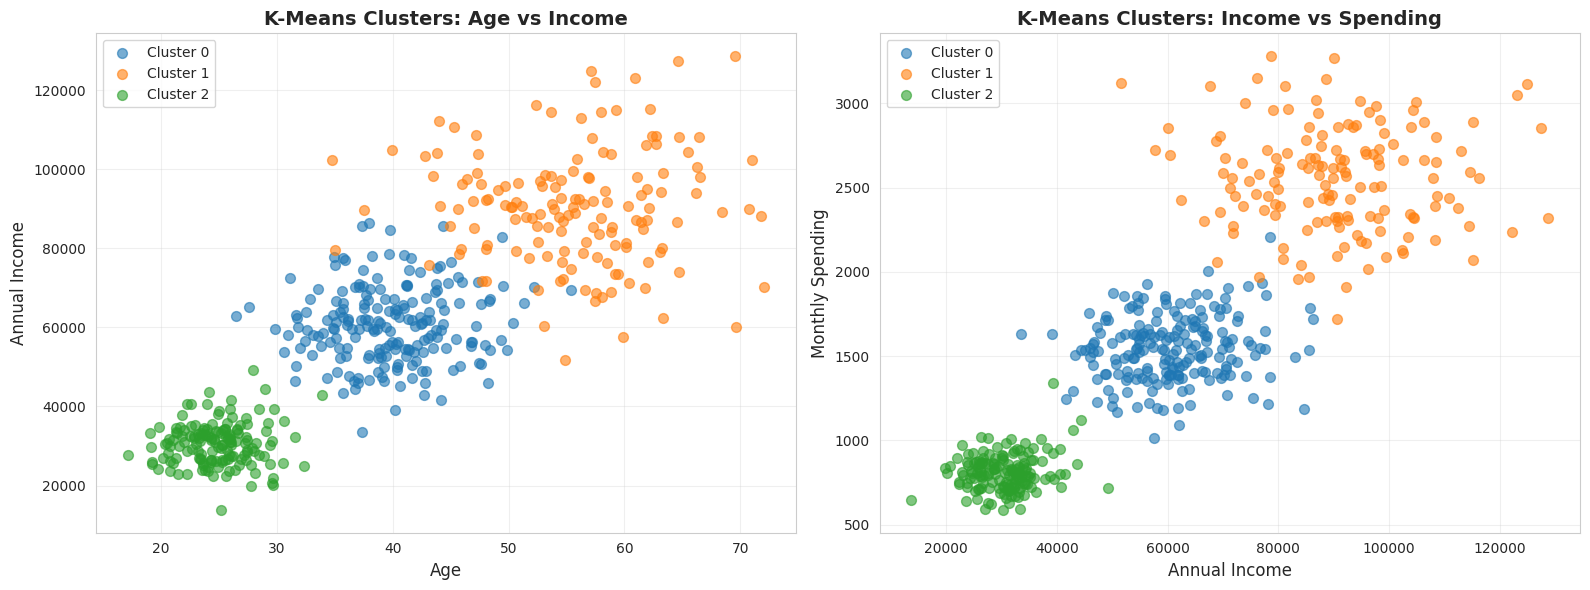

In [37]:
# Visualize K-Means clusters
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Age vs Income
for cluster in range(optimal_k):
    cluster_data = customer_data[customer_data['KMeans_Cluster'] == cluster]
    axes[0].scatter(cluster_data['Age'], cluster_data['Annual_Income'], 
                   label=f'Cluster {cluster}', alpha=0.6, s=50)
axes[0].set_xlabel('Age', fontsize=12)
axes[0].set_ylabel('Annual Income', fontsize=12)
axes[0].set_title('K-Means Clusters: Age vs Income', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Income vs Spending
for cluster in range(optimal_k):
    cluster_data = customer_data[customer_data['KMeans_Cluster'] == cluster]
    axes[1].scatter(cluster_data['Annual_Income'], cluster_data['Monthly_Spending'], 
                   label=f'Cluster {cluster}', alpha=0.6, s=50)
axes[1].set_xlabel('Annual Income', fontsize=12)
axes[1].set_ylabel('Monthly Spending', fontsize=12)
axes[1].set_title('K-Means Clusters: Income vs Spending', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 1.6 DBSCAN - Density-Based Clustering
DBSCAN finds clusters based on density. It can:
- Find clusters of arbitrary shapes
- Identify outliers (noise points)
- Doesn't require specifying the number of clusters

In [38]:
# Apply DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=5)
customer_data['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

# Count clusters (excluding noise points labeled as -1)
n_clusters = len(set(customer_data['DBSCAN_Cluster'])) - (1 if -1 in customer_data['DBSCAN_Cluster'].values else 0)
n_noise = list(customer_data['DBSCAN_Cluster']).count(-1)

print(f"DBSCAN found {n_clusters} clusters")
print(f"Number of noise points (outliers): {n_noise}")
print("\nCluster Distribution:")
print(customer_data['DBSCAN_Cluster'].value_counts().sort_index())

DBSCAN found 2 clusters
Number of noise points (outliers): 15

Cluster Distribution:
DBSCAN_Cluster
-1     15
 0    352
 1    133
Name: count, dtype: int64


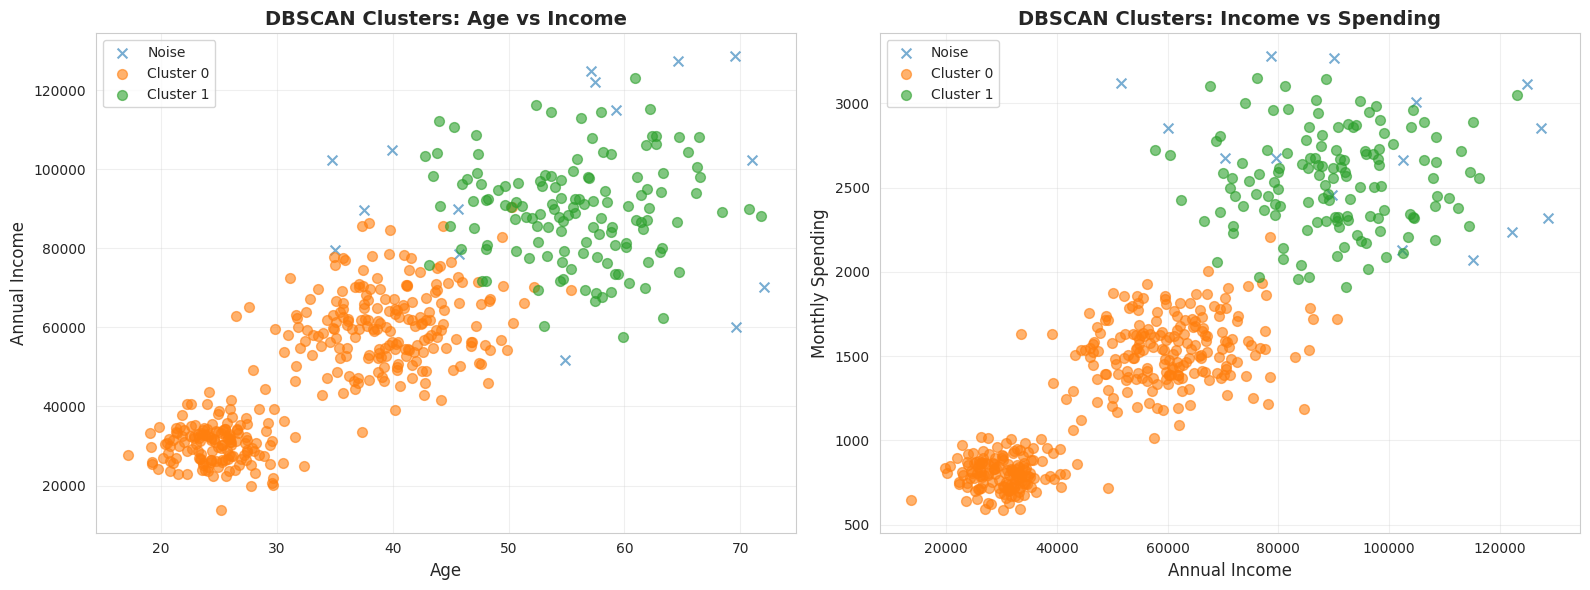

In [39]:
# Visualize DBSCAN clusters
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Get unique clusters
unique_clusters = sorted(customer_data['DBSCAN_Cluster'].unique())

# Plot 1: Age vs Income
for cluster in unique_clusters:
    cluster_data = customer_data[customer_data['DBSCAN_Cluster'] == cluster]
    label = 'Noise' if cluster == -1 else f'Cluster {cluster}'
    marker = 'x' if cluster == -1 else 'o'
    axes[0].scatter(cluster_data['Age'], cluster_data['Annual_Income'], 
                   label=label, alpha=0.6, s=50, marker=marker)
axes[0].set_xlabel('Age', fontsize=12)
axes[0].set_ylabel('Annual Income', fontsize=12)
axes[0].set_title('DBSCAN Clusters: Age vs Income', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Income vs Spending
for cluster in unique_clusters:
    cluster_data = customer_data[customer_data['DBSCAN_Cluster'] == cluster]
    label = 'Noise' if cluster == -1 else f'Cluster {cluster}'
    marker = 'x' if cluster == -1 else 'o'
    axes[1].scatter(cluster_data['Annual_Income'], cluster_data['Monthly_Spending'], 
                   label=label, alpha=0.6, s=50, marker=marker)
axes[1].set_xlabel('Annual Income', fontsize=12)
axes[1].set_ylabel('Monthly Spending', fontsize=12)
axes[1].set_title('DBSCAN Clusters: Income vs Spending', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 1.7 Geo-Segmentation Example
Clustering customers based on geographic location

In [40]:
# Create geographic data for Indian cities
np.random.seed(42)

# Major city centers (latitude, longitude)
cities = {
    'Mumbai': (19.0760, 72.8777),
    'Delhi': (28.7041, 77.1025),
    'Bangalore': (12.9716, 77.5946),
    'Chennai': (13.0827, 80.2707),
    'Kolkata': (22.5726, 88.3639)
}

# Generate customer locations around these cities
geo_data = []
for city, (lat, lon) in cities.items():
    n_customers_city = 100
    lats = np.random.normal(lat, 0.5, n_customers_city)
    lons = np.random.normal(lon, 0.5, n_customers_city)
    for i in range(n_customers_city):
        geo_data.append({
            'CustomerID': len(geo_data) + 1,
            'Latitude': lats[i],
            'Longitude': lons[i],
            'City': city
        })

geo_df = pd.DataFrame(geo_data)
print("Geographic Dataset Shape:", geo_df.shape)
geo_df.head()

Geographic Dataset Shape: (500, 4)


,CustomerID,Latitude,Longitude,City
0,1,19.324357,72.170015,Mumbai
1,2,19.006868,72.667377,Mumbai
2,3,19.399844,72.706343,Mumbai
3,4,19.837515,72.476561,Mumbai
4,5,18.958923,72.797057,Mumbai


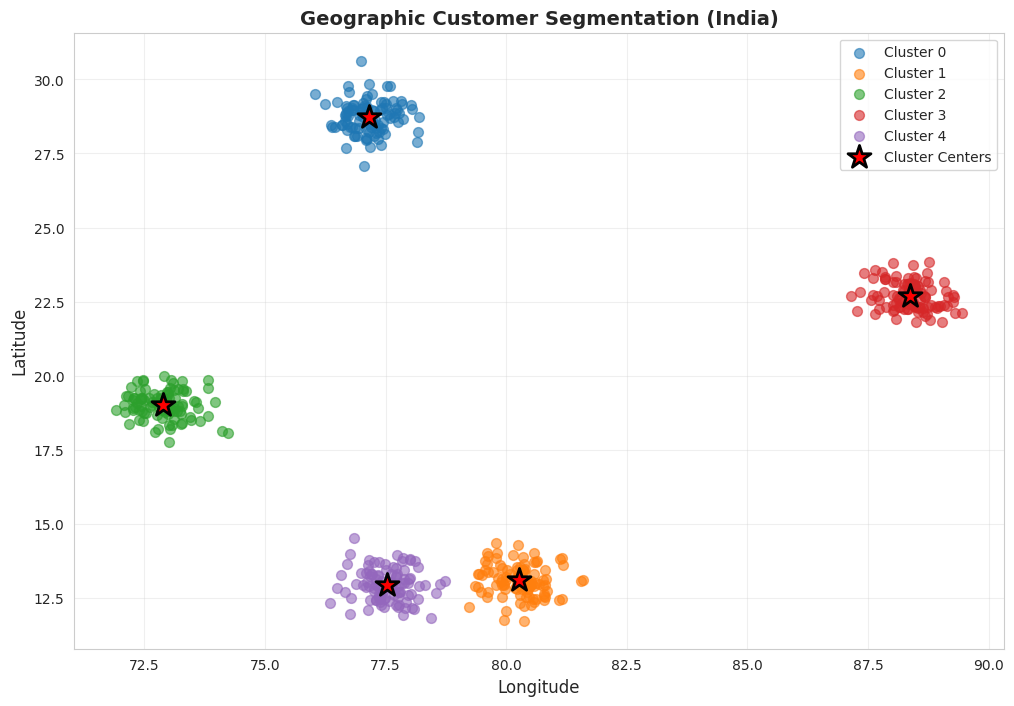


✅ Geo-segmentation helps businesses optimize delivery routes and regional marketing!


In [41]:
# Apply K-Means for geo-segmentation
geo_features = geo_df[['Latitude', 'Longitude']].values
geo_kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
geo_df['Geo_Cluster'] = geo_kmeans.fit_predict(geo_features)

# Visualize geo-clusters
plt.figure(figsize=(12, 8))
for cluster in range(5):
    cluster_data = geo_df[geo_df['Geo_Cluster'] == cluster]
    plt.scatter(cluster_data['Longitude'], cluster_data['Latitude'], 
               label=f'Cluster {cluster}', alpha=0.6, s=50)

# Plot cluster centers
centers = geo_kmeans.cluster_centers_
plt.scatter(centers[:, 1], centers[:, 0], c='red', marker='*', 
           s=300, edgecolors='black', linewidths=2, label='Cluster Centers')

plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.title('Geographic Customer Segmentation (India)', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("\n✅ Geo-segmentation helps businesses optimize delivery routes and regional marketing!")

---
# Topic 2: Market Segmentation Lab
---

## 2.1 Scaler Choice Comparison
Different scalers can affect clustering results. Let's compare:
- **StandardScaler**: Removes mean and scales to unit variance
- **MinMaxScaler**: Scales features to a range [0, 1]
- **RobustScaler**: Uses median and IQR (robust to outliers)

StandardScaler: Silhouette Score = 0.386
MinMaxScaler: Silhouette Score = 0.364
RobustScaler: Silhouette Score = 0.384


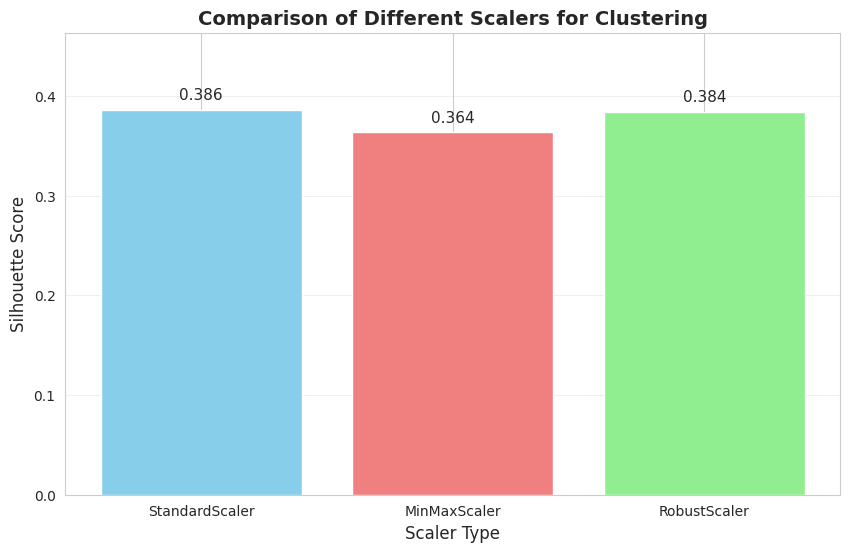


💡 StandardScaler is often the best choice for clustering!


In [42]:
# Prepare data
features_market = ['Age', 'Annual_Income', 'Monthly_Spending', 'Purchase_Frequency']
X_market = customer_data[features_market].values

# Apply different scalers
scalers = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler()
}

results = {}

for scaler_name, scaler in scalers.items():
    # Scale data
    X_scaled_temp = scaler.fit_transform(X_market)
    
    # Apply K-Means
    kmeans_temp = KMeans(n_clusters=3, random_state=42, n_init=10)
    labels = kmeans_temp.fit_predict(X_scaled_temp)
    
    # Calculate silhouette score
    sil_score = silhouette_score(X_scaled_temp, labels)
    
    results[scaler_name] = {
        'silhouette_score': sil_score,
        'labels': labels
    }
    
    print(f"{scaler_name}: Silhouette Score = {sil_score:.3f}")

# Visualize comparison
scaler_names = list(results.keys())
scores = [results[name]['silhouette_score'] for name in scaler_names]

plt.figure(figsize=(10, 6))
plt.bar(scaler_names, scores, color=['skyblue', 'lightcoral', 'lightgreen'])
plt.xlabel('Scaler Type', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.title('Comparison of Different Scalers for Clustering', fontsize=14, fontweight='bold')
plt.ylim(0, max(scores) * 1.2)
for i, score in enumerate(scores):
    plt.text(i, score + 0.01, f'{score:.3f}', ha='center', fontsize=11)
plt.grid(True, alpha=0.3, axis='y')
plt.show()

print("\n💡 StandardScaler is often the best choice for clustering!")

## 2.2 Final Market Segmentation with sklearn

In [43]:
# Use StandardScaler for final segmentation
final_scaler = StandardScaler()
X_final = final_scaler.fit_transform(X_market)

# Apply K-Means
final_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
customer_data['Market_Segment'] = final_kmeans.fit_predict(X_final)

print("Market Segmentation Complete!")
print("\nSegment Distribution:")
print(customer_data['Market_Segment'].value_counts().sort_index())

Market Segmentation Complete!

Segment Distribution:
Market_Segment
0    198
1    149
2    153
Name: count, dtype: int64


## 2.3 Persona Crafting
Creating customer personas based on cluster characteristics

In [44]:
# Analyze each segment
segment_profiles = customer_data.groupby('Market_Segment')[features_market].mean()

print("\n📊 CUSTOMER SEGMENT PROFILES\n")
print("="*80)
print(segment_profiles.round(2))
print("="*80)


📊 CUSTOMER SEGMENT PROFILES

                  Age  Annual_Income  Monthly_Spending  Purchase_Frequency
Market_Segment                                                            
0               39.82       60679.87           1544.80               14.87
1               55.58       90338.91           2552.13               15.55
2               24.86       30587.98            812.73               15.86


In [45]:
# Create detailed personas
personas = {
    0: {
        'name': 'Young Enthusiasts',
        'description': 'Young customers with lower income but high engagement',
        'characteristics': [
            'Age: 20-30 years',
            'Income: Lower range',
            'Spending: Moderate',
            'Frequency: High purchase frequency'
        ],
        'marketing_strategy': 'Focus on value deals, social media marketing, loyalty programs'
    },
    1: {
        'name': 'Established Professionals',
        'description': 'Middle-aged customers with stable income and spending',
        'characteristics': [
            'Age: 35-50 years',
            'Income: Medium range',
            'Spending: Moderate to high',
            'Frequency: Regular purchases'
        ],
        'marketing_strategy': 'Quality products, family packages, email marketing'
    },
    2: {
        'name': 'Premium Customers',
        'description': 'Older, high-income customers with premium spending',
        'characteristics': [
            'Age: 50+ years',
            'Income: High range',
            'Spending: High',
            'Frequency: Selective but valuable'
        ],
        'marketing_strategy': 'Premium products, personalized service, exclusive offers'
    }
}

# Display personas
for segment_id, persona in personas.items():
    print(f"\n{'='*80}")
    print(f"SEGMENT {segment_id}: {persona['name'].upper()}")
    print(f"{'='*80}")
    print(f"\nDescription: {persona['description']}")
    print(f"\nCharacteristics:")
    for char in persona['characteristics']:
        print(f"  • {char}")
    print(f"\nMarketing Strategy: {persona['marketing_strategy']}")
    print(f"\nSegment Size: {len(customer_data[customer_data['Market_Segment'] == segment_id])} customers")


SEGMENT 0: YOUNG ENTHUSIASTS

Description: Young customers with lower income but high engagement

Characteristics:
  • Age: 20-30 years
  • Income: Lower range
  • Spending: Moderate
  • Frequency: High purchase frequency

Marketing Strategy: Focus on value deals, social media marketing, loyalty programs

Segment Size: 198 customers

SEGMENT 1: ESTABLISHED PROFESSIONALS

Description: Middle-aged customers with stable income and spending

Characteristics:
  • Age: 35-50 years
  • Income: Medium range
  • Spending: Moderate to high
  • Frequency: Regular purchases

Marketing Strategy: Quality products, family packages, email marketing

Segment Size: 149 customers

SEGMENT 2: PREMIUM CUSTOMERS

Description: Older, high-income customers with premium spending

Characteristics:
  • Age: 50+ years
  • Income: High range
  • Spending: High
  • Frequency: Selective but valuable

Marketing Strategy: Premium products, personalized service, exclusive offers

Segment Size: 153 customers


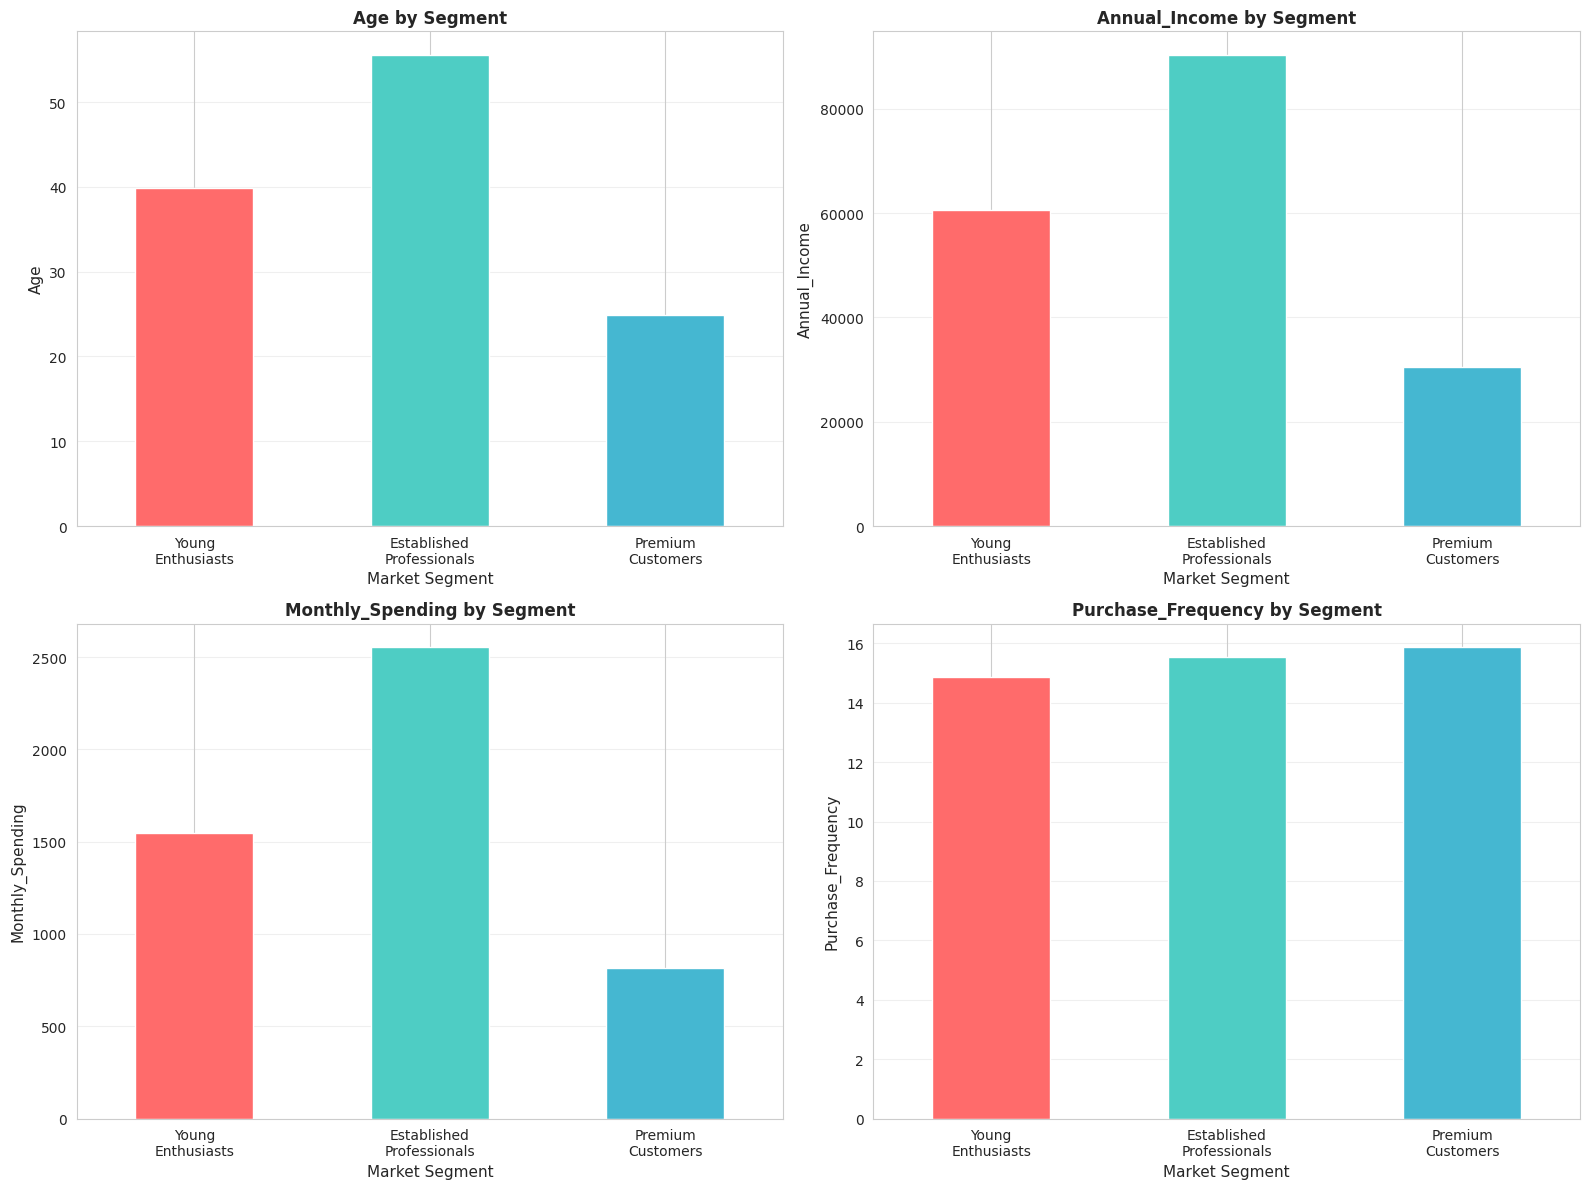

In [46]:
# Visualize segment profiles
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot each feature
for idx, feature in enumerate(features_market):
    ax = axes[idx // 2, idx % 2]
    segment_profiles[feature].plot(kind='bar', ax=ax, color=['#FF6B6B', '#4ECDC4', '#45B7D1'])
    ax.set_title(f'{feature} by Segment', fontsize=12, fontweight='bold')
    ax.set_xlabel('Market Segment', fontsize=11)
    ax.set_ylabel(feature, fontsize=11)
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_xticklabels(['Young\nEnthusiasts', 'Established\nProfessionals', 'Premium\nCustomers'], 
                       rotation=0)

plt.tight_layout()
plt.show()

---
# Topic 3: Visualizing Clusters
---

## 3.1 UMAP - Dimensionality Reduction
UMAP (Uniform Manifold Approximation and Projection) reduces high-dimensional data to 2D/3D for visualization while preserving structure.

In [47]:
# Apply UMAP for dimensionality reduction
umap_reducer = umap.UMAP(n_components=2, random_state=42, n_neighbors=15, min_dist=0.1)
X_umap = umap_reducer.fit_transform(X_final)

# Add UMAP coordinates to dataframe
customer_data['UMAP_1'] = X_umap[:, 0]
customer_data['UMAP_2'] = X_umap[:, 1]

print("✅ UMAP dimensionality reduction complete!")
print(f"Original dimensions: {X_final.shape[1]}")
print(f"Reduced dimensions: {X_umap.shape[1]}")

✅ UMAP dimensionality reduction complete!
Original dimensions: 4
Reduced dimensions: 2


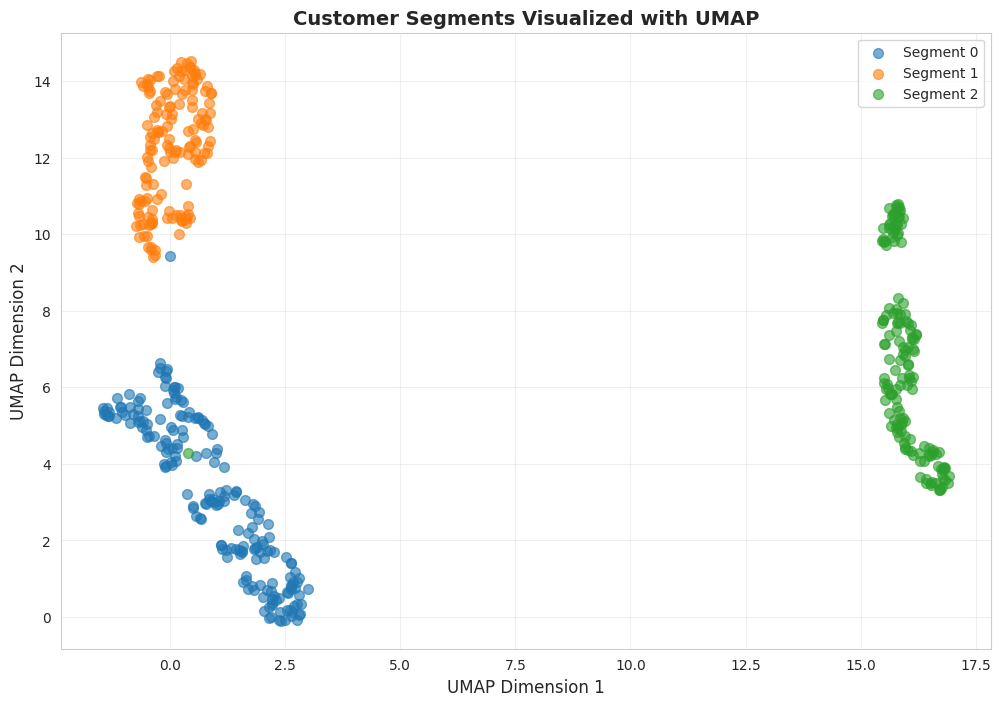


💡 UMAP helps visualize high-dimensional clusters in 2D!


In [48]:
# Visualize UMAP projection
plt.figure(figsize=(12, 8))
for segment in range(3):
    segment_data = customer_data[customer_data['Market_Segment'] == segment]
    plt.scatter(segment_data['UMAP_1'], segment_data['UMAP_2'], 
               label=f'Segment {segment}', alpha=0.6, s=50)

plt.xlabel('UMAP Dimension 1', fontsize=12)
plt.ylabel('UMAP Dimension 2', fontsize=12)
plt.title('Customer Segments Visualized with UMAP', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("\n💡 UMAP helps visualize high-dimensional clusters in 2D!")

## 3.2 Interactive Visualization with Plotly (Hover Effects)

In [49]:
# Create interactive scatter plot with hover information
fig = px.scatter(
    customer_data,
    x='UMAP_1',
    y='UMAP_2',
    color='Market_Segment',
    hover_data={
        'CustomerID': True,
        'Age': ':.0f',
        'Annual_Income': ':,.0f',
        'Monthly_Spending': ':,.0f',
        'Purchase_Frequency': True,
        'UMAP_1': False,
        'UMAP_2': False
    },
    title='Interactive Customer Segmentation (Hover for Details)',
    labels={'Market_Segment': 'Segment'},
    color_continuous_scale='Viridis',
    width=900,
    height=600
)

fig.update_traces(marker=dict(size=8, opacity=0.7))
fig.update_layout(
    font=dict(size=12),
    title_font_size=16,
    hoverlabel=dict(bgcolor="white", font_size=12)
)

fig.show()

print("\n✨ Hover over points to see customer details!")


✨ Hover over points to see customer details!


In [50]:
# Create 3D interactive visualization
fig_3d = px.scatter_3d(
    customer_data,
    x='Age',
    y='Annual_Income',
    z='Monthly_Spending',
    color='Market_Segment',
    hover_data={
        'CustomerID': True,
        'Purchase_Frequency': True,
        'Years_Customer': True
    },
    title='3D Customer Segmentation (Interactive)',
    labels={'Market_Segment': 'Segment'},
    color_continuous_scale='Portland',
    width=900,
    height=700
)

fig_3d.update_traces(marker=dict(size=5, opacity=0.7))
fig_3d.update_layout(
    scene=dict(
        xaxis_title='Age',
        yaxis_title='Annual Income',
        zaxis_title='Monthly Spending'
    ),
    font=dict(size=12)
)

fig_3d.show()

print("\n✨ Rotate and zoom the 3D plot to explore clusters from different angles!")


✨ Rotate and zoom the 3D plot to explore clusters from different angles!


## 3.3 Geographic Visualization with Interactive Maps

In [51]:
# Create interactive geographic map
fig_geo = px.scatter_mapbox(
    geo_df,
    lat='Latitude',
    lon='Longitude',
    color='Geo_Cluster',
    hover_data={
        'CustomerID': True,
        'City': True,
        'Latitude': ':.4f',
        'Longitude': ':.4f'
    },
    title='Geographic Customer Clusters (India)',
    zoom=4,
    center={'lat': 20.5937, 'lon': 78.9629},
    mapbox_style='open-street-map',
    width=900,
    height=700,
    color_continuous_scale='Rainbow'
)

fig_geo.update_traces(marker=dict(size=8, opacity=0.7))
fig_geo.update_layout(
    font=dict(size=12),
    title_font_size=16
)

fig_geo.show()

print("\n🗺️ Interactive map showing geographic customer clusters across India!")
print("   Zoom in/out and hover over points to see details.")


🗺️ Interactive map showing geographic customer clusters across India!
   Zoom in/out and hover over points to see details.


## 3.4 Cluster Comparison Dashboard

In [52]:
# Create comprehensive comparison plot
from plotly.subplots import make_subplots

fig_dashboard = make_subplots(
    rows=2, cols=2,
    subplot_titles=('Age Distribution', 'Income Distribution', 
                   'Spending Distribution', 'Purchase Frequency'),
    specs=[[{'type': 'box'}, {'type': 'box'}],
           [{'type': 'box'}, {'type': 'box'}]]
)

# Add box plots for each feature by segment
for segment in range(3):
    segment_data = customer_data[customer_data['Market_Segment'] == segment]
    
    # Age
    fig_dashboard.add_trace(
        go.Box(y=segment_data['Age'], name=f'Segment {segment}', showlegend=False),
        row=1, col=1
    )
    
    # Income
    fig_dashboard.add_trace(
        go.Box(y=segment_data['Annual_Income'], name=f'Segment {segment}', showlegend=False),
        row=1, col=2
    )
    
    # Spending
    fig_dashboard.add_trace(
        go.Box(y=segment_data['Monthly_Spending'], name=f'Segment {segment}', showlegend=False),
        row=2, col=1
    )
    
    # Frequency
    fig_dashboard.add_trace(
        go.Box(y=segment_data['Purchase_Frequency'], name=f'Segment {segment}', showlegend=False),
        row=2, col=2
    )

fig_dashboard.update_layout(
    title_text='Customer Segment Comparison Dashboard',
    title_font_size=18,
    height=800,
    showlegend=False
)

fig_dashboard.show()

print("\n📊 Interactive dashboard comparing all segments across key metrics!")


📊 Interactive dashboard comparing all segments across key metrics!


---
## Summary and Key Takeaways
---

### 🎯 What We Learned:

#### **Topic 1: K-Means & DBSCAN**
- ✅ **Distance Metrics**: Different ways to measure similarity (Euclidean, Manhattan, Cosine)
- ✅ **Elbow Method**: Find optimal number of clusters by looking for the "elbow" in WCSS plot
- ✅ **Silhouette Analysis**: Measure cluster quality (higher score = better clusters)
- ✅ **K-Means**: Fast algorithm that groups data into K spherical clusters
- ✅ **DBSCAN**: Density-based clustering that finds arbitrary shapes and identifies outliers
- ✅ **Geo-Segmentation**: Clustering customers by geographic location

#### **Topic 2: Market Segmentation**
- ✅ **Scaler Choice**: StandardScaler, MinMaxScaler, and RobustScaler comparison
- ✅ **sklearn Clustering**: Using scikit-learn for professional market segmentation
- ✅ **Persona Crafting**: Creating actionable customer personas from cluster analysis

#### **Topic 3: Visualization**
- ✅ **UMAP**: Reduce high-dimensional data to 2D while preserving structure
- ✅ **Interactive Plots**: Plotly for hover effects and exploration
- ✅ **Geographic Maps**: Visualizing clusters on actual maps
- ✅ **Dashboards**: Comprehensive comparison views

### 💡 Practical Applications:
1. **Marketing**: Target different customer segments with personalized campaigns
2. **Retail**: Optimize store locations based on geographic clustering
3. **E-commerce**: Recommend products based on customer segment
4. **Logistics**: Plan delivery routes using geo-segmentation
5. **Product Development**: Design features for specific customer personas

### 🚀 Next Steps:
- Try different datasets from Kaggle or government sources
- Experiment with different numbers of clusters
- Combine multiple clustering algorithms
- Add more features to improve segmentation
- Deploy models in real business scenarios

In [53]:
# Final summary statistics
print("\n" + "="*80)
print("FINAL CLUSTERING SUMMARY")
print("="*80)
print(f"\nTotal Customers Analyzed: {len(customer_data)}")
print(f"Number of Market Segments: 3")
print(f"\nSegment Sizes:")
for segment in range(3):
    count = len(customer_data[customer_data['Market_Segment'] == segment])
    percentage = (count / len(customer_data)) * 100
    print(f"  Segment {segment}: {count} customers ({percentage:.1f}%)")

print(f"\nClustering Quality:")
final_silhouette = silhouette_score(X_final, customer_data['Market_Segment'])
print(f"  Silhouette Score: {final_silhouette:.3f}")

print("\n" + "="*80)
print("✅ DEMO COMPLETE! You now understand unsupervised learning clustering!")
print("="*80)


FINAL CLUSTERING SUMMARY

Total Customers Analyzed: 500
Number of Market Segments: 3

Segment Sizes:
  Segment 0: 198 customers (39.6%)
  Segment 1: 149 customers (29.8%)
  Segment 2: 153 customers (30.6%)

Clustering Quality:
  Silhouette Score: 0.386

✅ DEMO COMPLETE! You now understand unsupervised learning clustering!
